#### In this notebook, we test the 'minimally' updated `GWhyp` against the original GWhyp and benchmark it by comparing the two for random values of signal parameters.

In [1]:
#Import libraries
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Import user-defined modules
import sys
sys.path.append('/home/vidit-singh/Fstat_GWhyp/GWhyp_explore/src/')
from constants import *
from gw_hyp_valid import hyp_pta_res
from gw_hyp_valid_updated import hyp_pta_res_updated

In [3]:
#Parameter values
M = 1e10                                         #Total mass
q = 1                                            #Mass ratio (equal masses)
e = 1.15                                         #Eccentricity
n = 1e-8                                         #Characteristic frequency
i = np.pi/3                                      #Inclination angle
D = 1.6 * 1e9 * pc                               #Distance to the GW source
RA_GW = 0.5                                      #RA of the GW source
DEC_GW = 0.75                                    #DEC of the GW source
psi = 0                                          #GW polarization angle
theta = 1.4859551334842158                       #Theta(pulsar)
phi = 0.13289445709978395                        #Phi(pulsar)
tarr = np.linspace(-10, 10, 2000) * yr           #ToAs 
tref = 0                                         #Reference epoch

In [4]:
#Some derived parameter values
x = (M * tsun * n)**(2/3)                        #PN-expansion parameter
eta = q / (1 + q)**2                             #Symmetric mass ratio
cos_inc = np.cos(i)                              #cos(inclination)
S = ((M * dsun)* x * eta) /(D * n)               #PTA signal amplitude

In [5]:
print(x)
print(n)
print(eta)
print(cos_inc)
print(S)

0.006236865093640323
1e-08
0.25
0.5000000000000001
4.663436409523851e-08


In [6]:
#The parameter dictionary
gwhyp_params = {
    "cos_gwtheta": np.sin(DEC_GW),
    "gwphi": RA_GW,
    "psi": psi,
    "cos_inc": cos_inc,
    "log10_M": np.log10(M),
    "q": q,
    "log10_S":np.log10(S),
    "tref": tref,
    "theta": theta,
    "phi": phi
}

#### Benchmarking for $\Phi_0 = 0$

In [7]:
#GWhyp residuals
res_gwhyp = hyp_pta_res(toas = tarr, log10_n = np.log10(n), e0 = e, cons_terms = True, **gwhyp_params)
#GWhyp_updated residuals
res_updated = hyp_pta_res_updated(toas = tarr, log10_n = np.log10(n), e0 = e, phi0 = 0, cons_off = None, **gwhyp_params)

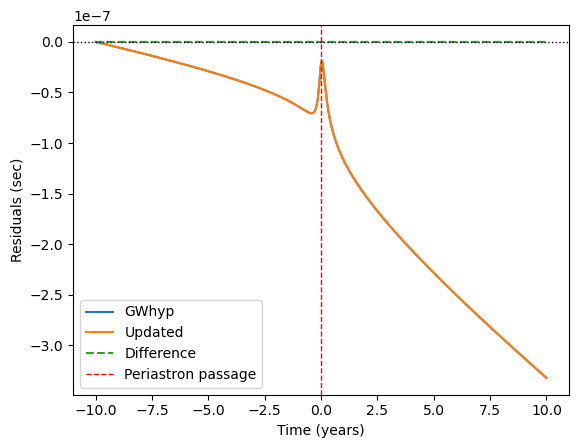

In [11]:
#Plot and compare
plt.plot(tarr / yr, res_gwhyp, label = 'GWhyp')
plt.plot(tarr / yr, res_updated, label = 'Updated')
plt.plot(tarr / yr, res_gwhyp - res_updated, label = 'Difference', linestyle = '--')
plt.axhline(y = 0, color='black', linestyle=':', linewidth=1, alpha=1.0)
plt.axvline(x = tref / yr, color='red', linestyle='--', linewidth=1, alpha=1.0, label = 'Periastron passage')
plt.xlabel('Time (years)')
plt.ylabel('Residuals (sec)')
plt.legend()
plt.show()

In [13]:
#Print the maximum difference [should be zero within numerical precision]
diff = res_gwhyp - res_updated
print(max(np.abs(diff)))

5.498768029157542e-13


#### Effect of $\Phi_0 \neq 0$ 

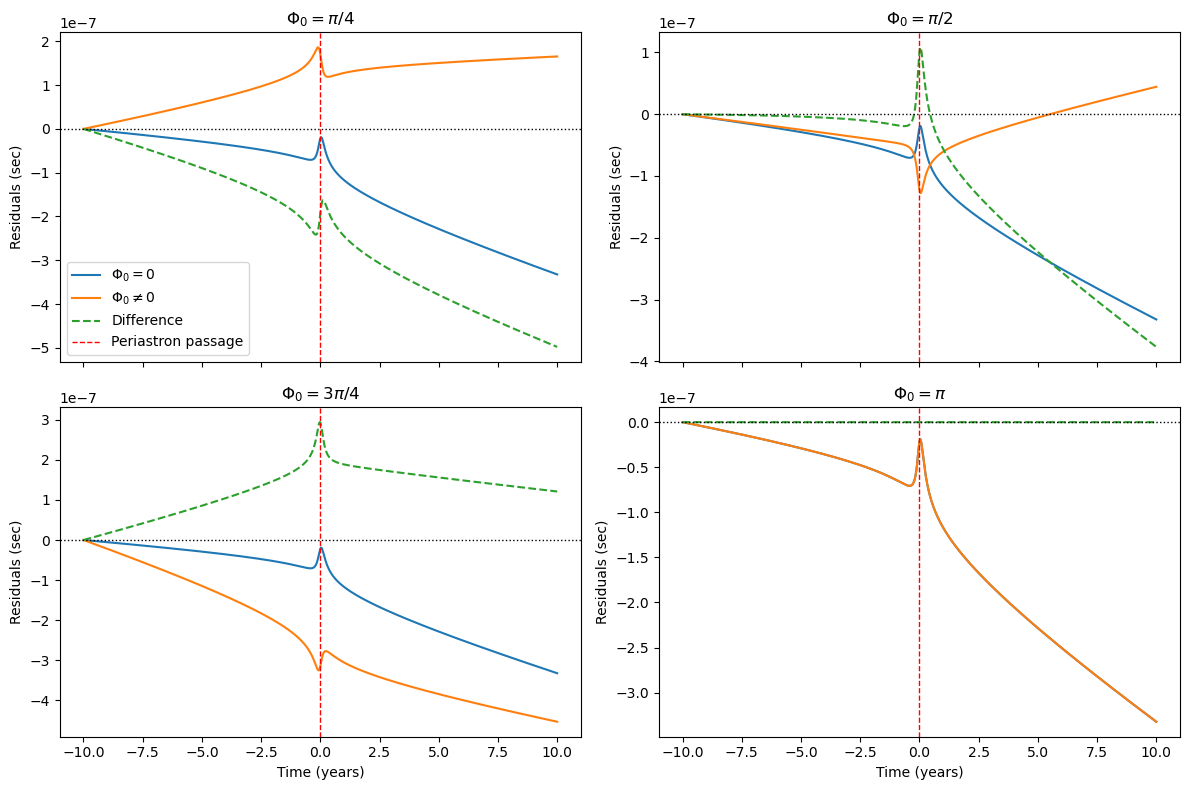

In [18]:
phi0_values = [np.pi/4, np.pi/2, 3*np.pi/4, np.pi]

phi0_labels = [
    r'$\pi/4$',
    r'$\pi/2$',
    r'$3\pi/4$',
    r'$\pi$'
]

res_phi0 = hyp_pta_res_updated(
    toas=tarr,
    log10_n=np.log10(n),
    e0=e,
    phi0=0,
    cons_off=None,
    **gwhyp_params
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axes = axes.flatten()

for i, (ax, phi0, phi0_label) in enumerate(
    zip(axes, phi0_values, phi0_labels)
):

    res_new = hyp_pta_res_updated(
        toas=tarr,
        log10_n=np.log10(n),
        e0=e,
        phi0=phi0,
        cons_off=None,
        **gwhyp_params
    )

    ax.plot(tarr / yr, res_phi0, label=r'$\Phi_0=0$')
    ax.plot(tarr / yr, res_new, label=r'$\Phi_0 \neq 0$')
    ax.plot(
        tarr / yr,
        res_phi0 - res_new,
        label='Difference',
        linestyle='--'
    )

    ax.axhline(y=0, color='black', linestyle=':', linewidth=1)

    ax.axvline(
        x=tref / yr,
        color='red',
        linestyle='--',
        linewidth=1,
        label='Periastron passage'
    )

    # Preserve the original subplot titles
    ax.set_title(rf'$\Phi_0={phi0_label[1:-1]}$')
    ax.set_ylabel('Residuals (sec)')

    # Display the legend only in the first subplot
    if i == 0:
        ax.legend()

axes[2].set_xlabel('Time (years)')
axes[3].set_xlabel('Time (years)')

plt.tight_layout()
plt.show()

#### Can the effect of $\Phi_0 \neq 0$ be absorbed in a quadratic fit?

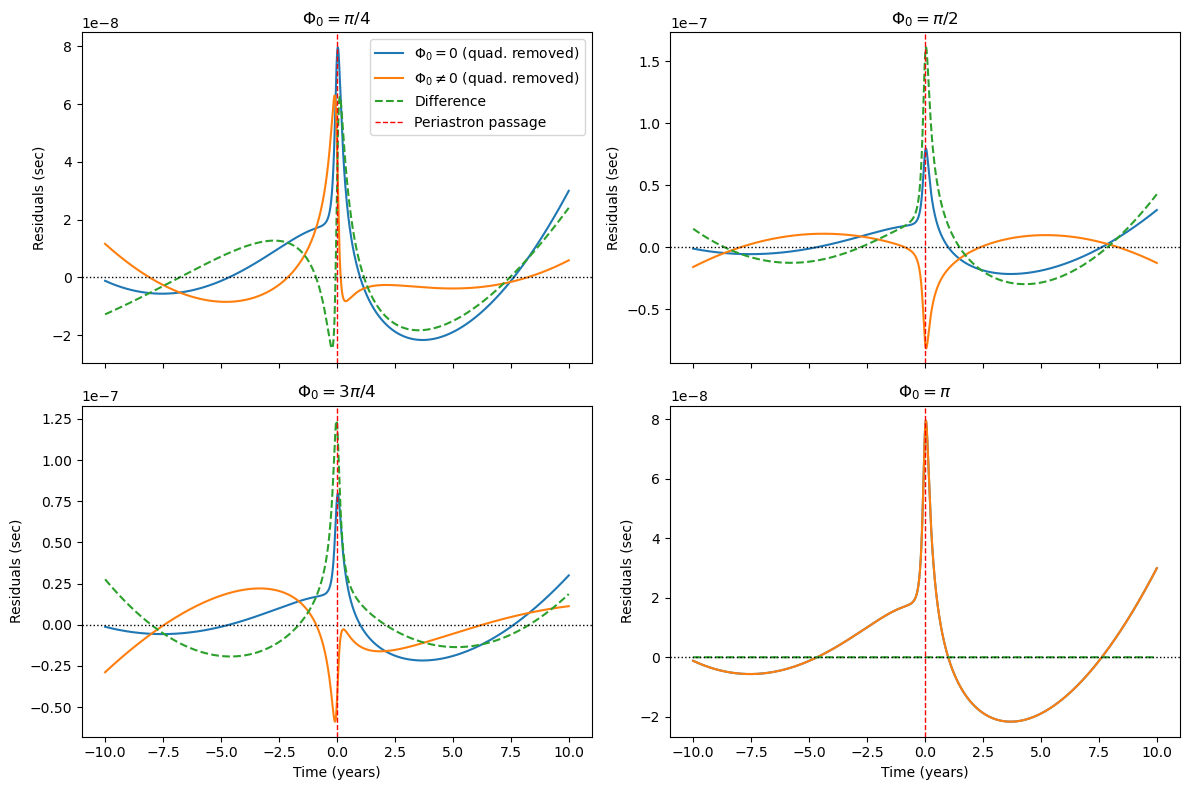

In [24]:
phi0_values = [np.pi/4, np.pi/2, 3*np.pi/4, np.pi]

phi0_labels = [
    r'$\pi/4$',
    r'$\pi/2$',
    r'$3\pi/4$',
    r'$\pi$'
]

res_phi0 = hyp_pta_res_updated(
    toas=tarr,
    log10_n=np.log10(n),
    e0=e,
    phi0=0,
    cons_off=None,
    **gwhyp_params
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axes = axes.flatten()

# Time in years, centered for numerical stability
t_years = tarr / yr
t_centered = t_years - np.mean(t_years)

# Fit a quadratic to the zero-phi0 residuals
coeffs_phi0 = np.polynomial.polynomial.polyfit(
    t_centered,
    res_phi0,
    deg=2
)

quadratic_fit_phi0 = np.polynomial.polynomial.polyval(
    t_centered,
    coeffs_phi0
)

# Subtract the quadratic from the zero-phi0 residuals
res_phi0_detrended = res_phi0 - quadratic_fit_phi0

for i, (ax, phi0, phi0_label) in enumerate(
    zip(axes, phi0_values, phi0_labels)
):

    res_new = hyp_pta_res_updated(
        toas=tarr,
        log10_n=np.log10(n),
        e0=e,
        phi0=phi0,
        cons_off=None,
        **gwhyp_params
    )

    # Fit a quadratic to the nonzero-phi0 residuals
    coeffs = np.polynomial.polynomial.polyfit(
        t_centered,
        res_new,
        deg=2
    )

    quadratic_fit = np.polynomial.polynomial.polyval(
        t_centered,
        coeffs
    )

    # Subtract the quadratic from the nonzero-phi0 residuals
    res_new_detrended = res_new - quadratic_fit

    # Plot both detrended residual curves
    ax.plot(
        t_years,
        res_phi0_detrended,
        label=r'$\Phi_0=0$ (quad. removed)'
    )

    ax.plot(
        t_years,
        res_new_detrended,
        label=r'$\Phi_0\neq0$ (quad. removed)'
    )

    # Difference between the detrended curves
    ax.plot(
        t_years,
        res_phi0_detrended - res_new_detrended,
        label='Difference',
        linestyle='--'
    )

    ax.axhline(
        y=0,
        color='black',
        linestyle=':',
        linewidth=1
    )

    ax.axvline(
        x=tref / yr,
        color='red',
        linestyle='--',
        linewidth=1,
        label='Periastron passage'
    )

    # Preserve the original subplot titles
    ax.set_title(rf'$\Phi_0={phi0_label[1:-1]}$')
    ax.set_ylabel('Residuals (sec)')

    # Display the legend only in the first subplot
    if i == 0:
        ax.legend()

axes[2].set_xlabel('Time (years)')
axes[3].set_xlabel('Time (years)')

plt.tight_layout()
plt.show()

#### This clearly shows the need for $\Phi_0$ to be included as a free parameter explicitly while modeling the LGWM signal.